In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Core function

In [5]:
def monte_carlo_pi(n_samples: int, seed: int = 42):
    """
    Estimate pi using the Monte Carlo method.

    Idea: randomly scatter points inside a unit square.
    The probability a point falls inside the inscribed circle
    is pi/4, so pi can be estimated from that ratio.

    Args:
        n_samples: number of random points to generate
        seed: random seed for reproducibility

    Returns:
        x, y: coordinates of all sampled points
        inside: boolean array, True if point is inside the circle
        pi_estimate: estimated value of pi
    """
    rng = np.random.default_rng(seed)

    x = rng.random(n_samples)
    y = rng.random(n_samples)

    inside = ((x - 0.5) ** 2 + (y - 0.5) ** 2) <= 0.25
    pi_estimate = 4 * inside.sum() / n_samples

    return x, y, inside, pi_estimate

# Visualization 1: Scatter plot of sampled points

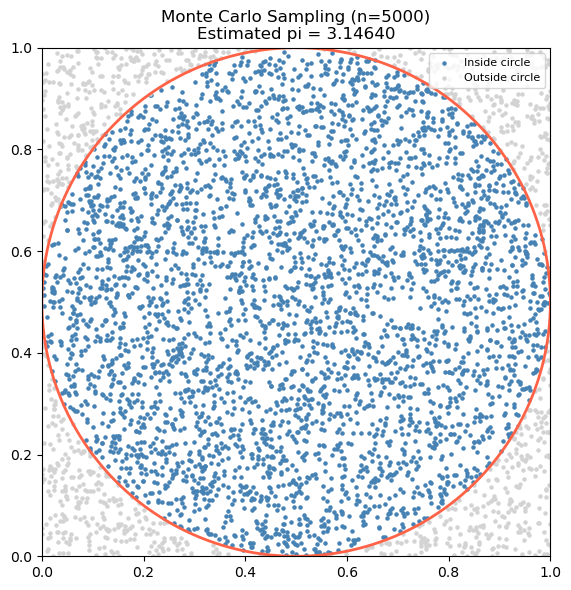

In [8]:
n_samples = 5000
x, y, inside, pi_est = monte_carlo_pi(n_samples)

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(x[inside], y[inside], color='steelblue', s=5, label='Inside circle')
ax.scatter(x[~inside], y[~inside], color='lightgray', s=5, label='Outside circle')

# Draw the circle boundary
theta = np.linspace(0, 2 * np.pi, 200)
circle_x = 0.5 + 0.5 * np.cos(theta)
circle_y = 0.5 + 0.5 * np.sin(theta)
ax.plot(circle_x, circle_y, color='tomato', lw=2)

ax.set_aspect('equal')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title(f'Monte Carlo Sampling (n={n_samples})\nEstimated pi = {pi_est:.5f}')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.savefig('monte_carlo_scatter.png', dpi=150)
plt.show()


### Monte Carlo Sampling (n=5000)

With 5,000 random points, the estimated value of π is 3.14640 — within 0.0048 of the true value. Blue points fall inside the inscribed circle, gray points fall outside. The blue region visually fills the circular area while gray points concentrate in the four corners, making the geometric basis of the estimation immediately intuitive: the ratio of blue to total points approximates π/4.

在5000个随机点的情况下，π的估计值为3.14640，与真实值的误差仅为0.0048。蓝色点落在内切圆内，灰色点落在圆外。蓝色区域直观填满了圆形区域，灰色点集中在四个角落，让”用比例估计π”这一几何原理一目了然：蓝点占总点数的比例近似于π/4。

# Visualization 2: Convergence as sample size grows

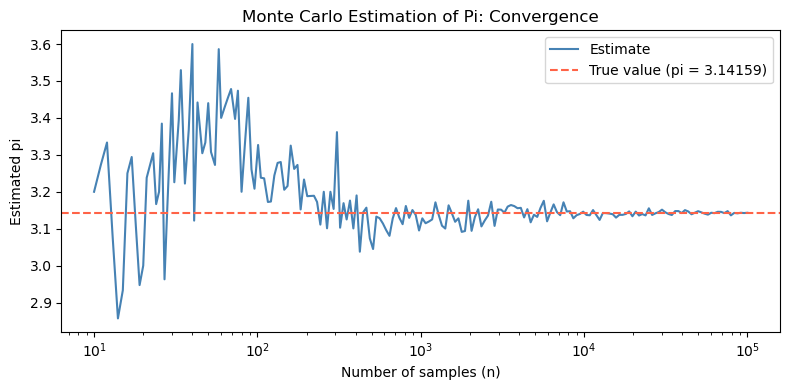

In [11]:
def plot_convergence(max_n: int = 100_000, n_points: int = 200):
    """Plot how the estimate converges to pi as sample size grows."""
    ns = np.logspace(1, np.log10(max_n), n_points).astype(int)
    estimates = [monte_carlo_pi(n)[3] for n in ns]

    plt.figure(figsize=(8, 4))
    plt.semilogx(ns, estimates, color='steelblue', lw=1.5, label='Estimate')
    plt.axhline(np.pi, color='tomato', lw=1.5, ls='--',
                label=f'True value (pi = {np.pi:.5f})')
    plt.xlabel('Number of samples (n)')
    plt.ylabel('Estimated pi')
    plt.title('Monte Carlo Estimation of Pi: Convergence')
    plt.legend()
    plt.tight_layout()
    plt.savefig('pi_convergence.png', dpi=150)
    plt.show()

plot_convergence()

### Convergence Plot

The estimate fluctuates wildly for small sample sizes (n < 100), swinging between 2.87 and 3.60. As n grows beyond 1,000, the curve narrows and hugs the true value (red dashed line) increasingly closely. By n = 100,000 the oscillations are barely visible. This is the law of large numbers in action: random noise averages out as the sample size grows, pulling the estimate toward the true value.


在样本量较小时（n < 100），估计值剧烈波动，在2.87到3.60之间大幅振荡。随着n超过1000，曲线逐渐收窄并紧贴真实值（红色虚线）。到n = 100,000时振荡已几乎不可见。这正是大数定律的直观体现：随着样本量增大，随机噪声相互抵消，估计值趋向真实值。

# Error vs. sample size (log-log plot)

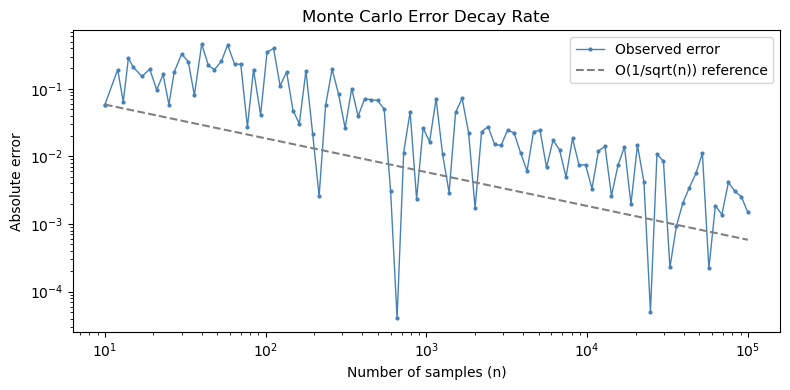

In [14]:
ns = np.logspace(1, 5, 100).astype(int)
errors = [abs(monte_carlo_pi(n)[3] - np.pi) for n in ns]

plt.figure(figsize=(8, 4))
plt.loglog(ns, errors, color='steelblue', lw=1, marker='o', markersize=2, label='Observed error')

# Reference line for O(1/sqrt(n)) decay
ref = errors[0] * np.sqrt(ns[0] / ns)
plt.loglog(ns, ref, color='gray', lw=1.5, ls='--', label='O(1/sqrt(n)) reference')

plt.xlabel('Number of samples (n)')
plt.ylabel('Absolute error')
plt.title('Monte Carlo Error Decay Rate')
plt.legend()
plt.tight_layout()
plt.savefig('pi_error_decay.png', dpi=150)
plt.show()

### Error Decay Rate

On a log-log scale, the observed error (blue) follows a broadly downward trend consistent with the O(1/√n) reference line (gray dashed). The error at n=100 is around 0.02–0.1, dropping to roughly 0.001–0.01 at n=10,000. The high volatility in the observed curve is expected — each run uses a fixed seed, so individual estimates can get lucky or unlucky. The overall trend confirms the theoretical convergence rate: to halve the error, you need to quadruple the sample size.

在log-log坐标下，观测误差（蓝色）整体呈向下趋势，与$O(1/√n)$理论参考线（灰色虚线）基本吻合。n=100时误差约为0.02-0.1，n=10,000时降至约0.001-0.01。曲线波动较大是正常现象——每次运行使用固定种子，个别估计值可能”走运”或”不走运”。整体趋势验证了理论收敛速率：误差减半需要样本量增加到四倍。

# Summary table

In [17]:
print(f'{"n":>10} | {"pi estimate":>12} | {"error":>10}')
print('-' * 38)
for n in [100, 1_000, 10_000, 100_000, 1_000_000]:
    _, _, _, est = monte_carlo_pi(n)
    err = abs(est - np.pi)
    print(f'{n:>10,} | {est:>12.5f} | {err:>10.5f}')

         n |  pi estimate |      error
--------------------------------------
       100 |      3.12000 |    0.02159
     1,000 |      3.08000 |    0.06159
    10,000 |      3.12560 |    0.01599
   100,000 |      3.14308 |    0.00149
 1,000,000 |      3.14178 |    0.00019


### Summary Table

The table quantifies the convergence numerically. At n=100 the error is 0.022; at n=1,000,000 it drops to 0.00019 — roughly a 100× improvement for a 10,000× increase in sample size, consistent with the √n relationship. Note that n=1,000 gives a slightly worse estimate than n=100 in this run (0.062 vs 0.022) — a reminder that Monte Carlo results are random and a single run can be misleading; the convergence trend only becomes reliable on average across many runs.

这张表以具体数字量化了收敛过程。n=100时误差为0.022；n=1,000,000时误差降至0.00019——样本量增加10,000倍，误差改善约100倍，符合$√n$关系。值得注意的是，这次运行中n=1,000的结果反而比n=100更差（误差0.062 vs 0.022）——这提醒我们蒙特卡洛结果本质上是随机的，单次运行可能产生误导；收敛趋势只有在多次运行的平均意义上才稳定可靠。

# Monte Carlo $\Pi$ Estimation — Project Summary

This project estimates the value of π using the Monte Carlo method. The core idea is to randomly scatter points within a unit square and determine how many fall inside the inscribed circle. By geometric probability, the proportion of points landing inside the circle approximates π/4, allowing π to be estimated via:

$$
π≈4× \frac {total \ points}{points \ inside \ circle}
$$

The implementation uses NumPy's vectorized operations to generate random coordinates in batches and apply boolean indexing to efficiently classify each point as inside or outside the circle, avoiding slow explicit loops.

To illustrate the method's behavior, four complementary visualizations were built:

1. A **scatter plot** that makes the abstract "ratio-based estimation" process visually concrete, showing the actual distribution of sampled points relative to the circle boundary.

2. A **convergence plot** showing how the estimate stabilizes as the sample size grows — a direct visual demonstration of the law of large numbers, where increasing the number of samples reduces the influence of random fluctuation and pulls the estimate closer to the true value.

3. An **error decay plot** (log-log scale) that empirically verifies a theoretical property of the method: estimation error decreases at a rate of roughly $O(1/√n)$, consistent with the convergence rate implied by the central limit theorem.

4. A **summary table** providing concrete numerical results across different sample sizes, complementing the three plots above.


Overall, the project builds a complete narrative arc — from the underlying mechanism, to empirical convergence behavior, to theoretical verification — making it both an accessible introduction to Monte Carlo methods and a demonstration of basic statistical intuition and numerical experiment design.

## 中文版 Monte Carlo 估计 π 项目总结 

本项目使用蒙特卡洛方法（Monte Carlo Method）估计圆周率 π 的值。核心思路是：在一个边长为1的正方形内随机撒点，并判断每个点是否落在内切圆内。根据几何概率关系，圆内点数占总点数的比例约等于 π/4，因此可以反推出 π 的估计值，公式为：

$$
π ≈ 4×
\frac{总点数}{圆内点数}
$$

代码中使用 NumPy 的向量化运算批量生成随机坐标，并通过布尔索引快速判断每个点是否落在圆内，避免使用低效的循环结构。


为了更直观地展示这一方法的效果，项目设计了四个层次的可视化：

1.散点图直接呈现随机点的分布情况，让"用比例估计π"这一抽象过程变得可视化；

2.收敛图展示了估计值随样本数增加而趋于稳定的过程，体现了大数定律的直观效果——样本越多，随机波动的影响越小，估计越接近真实值；

3.误差衰减图（log-log坐标）进一步验证了蒙特卡洛方法的理论性质：估计误差大致按照 $O(1/√n)$ 的速度下降，这与中心极限定理推导出的收敛速率一致

4.汇总表则以具体数字总结了不同样本量下的估计精度，作为前三张图的数值补充。

整体而言，该项目从"方法原理"到"收敛趋势"再到"理论验证"，构建了一条完整的展示逻辑，既适合作为蒙特卡洛方法的入门教学示例，也展示了基本的统计直觉与数值实验设计能力。